In [2]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

In [4]:
df=pd.read_csv(r"C:\Users\manav\OneDrive\Desktop\reviews.csv")
df.head(5)

,Time_submitted,Review,Rating,Total_thumbsup,Reply
0,2022-07-09 15:00:00,"Great music service, the audio is high quality...",5,2,NaN
1,2022-07-09 14:21:22,Please ignore previous negative rating. This a...,5,1,NaN
2,2022-07-09 13:27:32,"This pop-up ""Get the best Spotify experience o...",4,0,NaN
3,2022-07-09 13:26:45,Really buggy and terrible to use as of recently,1,1,NaN
4,2022-07-09 13:20:49,Dear Spotify why do I get songs that I didn't ...,1,1,NaN


In [5]:
df.describe()

,Rating,Total_thumbsup
count,61594.000000,61594.000000
mean,3.155989,7.649381
std,1.673285,89.323143
min,1.000000,0.000000
25%,1.000000,0.000000
50%,3.000000,0.000000
75%,5.000000,1.000000
max,5.000000,8195.000000


In [6]:
df.dtypes

Time_submitted      str
Review              str
Rating            int64
Total_thumbsup    int64
Reply               str
dtype: object

In [7]:
df.isnull().any()

Time_submitted    False
Review            False
Rating            False
Total_thumbsup    False
Reply              True
dtype: bool

In [8]:
df.isnull().sum()

Time_submitted        0
Review                0
Rating                0
Total_thumbsup        0
Reply             61378
dtype: int64

In [9]:
df['Reply']=df['Reply'].fillna("No Reply")

In [10]:
df['Reply'].isnull().sum()

np.int64(0)

In [11]:
df['Time_submitted']=pd.to_datetime(df['Time_submitted'])

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61594 entries, 0 to 61593
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Time_submitted  61594 non-null  datetime64[us]
 1   Review          61594 non-null  str           
 2   Rating          61594 non-null  int64         
 3   Total_thumbsup  61594 non-null  int64         
 4   Reply           61594 non-null  str           
dtypes: datetime64[us](1), int64(2), str(2)
memory usage: 2.3 MB


In [13]:
df['year']=df['Time_submitted'].dt.year
df['month']=df['Time_submitted'].dt.month
df['day']=df['Time_submitted'].dt.day
df['hours']=df['Time_submitted'].dt.hour
df['min']=df['Time_submitted'].dt.minute
df['sec']=df['Time_submitted'].dt.second



In [14]:
df.head(5)

,Time_submitted,Review,Rating,Total_thumbsup,Reply,year,month,day,hours,min,sec
0,2022-07-09 15:00:00,"Great music service, the audio is high quality...",5,2,No Reply,2022,7,9,15,0,0
1,2022-07-09 14:21:22,Please ignore previous negative rating. This a...,5,1,No Reply,2022,7,9,14,21,22
2,2022-07-09 13:27:32,"This pop-up ""Get the best Spotify experience o...",4,0,No Reply,2022,7,9,13,27,32
3,2022-07-09 13:26:45,Really buggy and terrible to use as of recently,1,1,No Reply,2022,7,9,13,26,45
4,2022-07-09 13:20:49,Dear Spotify why do I get songs that I didn't ...,1,1,No Reply,2022,7,9,13,20,49


In [15]:
df=df.drop(columns='Time_submitted')

In [16]:
df.head(5)

,Review,Rating,Total_thumbsup,Reply,year,month,day,hours,min,sec
0,"Great music service, the audio is high quality...",5,2,No Reply,2022,7,9,15,0,0
1,Please ignore previous negative rating. This a...,5,1,No Reply,2022,7,9,14,21,22
2,"This pop-up ""Get the best Spotify experience o...",4,0,No Reply,2022,7,9,13,27,32
3,Really buggy and terrible to use as of recently,1,1,No Reply,2022,7,9,13,26,45
4,Dear Spotify why do I get songs that I didn't ...,1,1,No Reply,2022,7,9,13,20,49


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61594 entries, 0 to 61593
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Review          61594 non-null  str  
 1   Rating          61594 non-null  int64
 2   Total_thumbsup  61594 non-null  int64
 3   Reply           61594 non-null  str  
 4   year            61594 non-null  int32
 5   month           61594 non-null  int32
 6   day             61594 non-null  int32
 7   hours           61594 non-null  int32
 8   min             61594 non-null  int32
 9   sec             61594 non-null  int32
dtypes: int32(6), int64(2), str(2)
memory usage: 3.3 MB


In [18]:
print(df.groupby(['year','month']).size())

year  month
2022  1         5231
      2         7458
      3         8023
      4        13803
      5        10922
      6        12257
      7         3900
dtype: int64


In [19]:
hourly_daily_ratings=df.groupby(['day','hours'])['Rating'].mean()
hourly_daily_ratings.head(5)

day  hours
1    0        3.445946
     1        3.309859
     2        3.442857
     3        3.518987
     4        3.222222
Name: Rating, dtype: float64

In [20]:
sorted_df=df[['Review','Total_thumbsup','Rating']].sort_values(by='Total_thumbsup',ascending=False)
sorted_df.head(5)

,Review,Total_thumbsup,Rating
36968,The app is very good. I got to explore many ne...,8195,4
37523,Forever glitchy. App play button and current s...,6026,1
4877,there was a drop down thing that I think has r...,5336,4
31673,2 years of use so far. This is my favorite app...,4791,4
35203,Fantastic app. Have always had a great experie...,4777,5


In [21]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns


In [23]:
rating_counts=df['Rating'].value_counts().reset_index()
print(rating_counts)

   Rating  count
0       5  22095
1       1  17653
2       4   7842
3       2   7118
4       3   6886


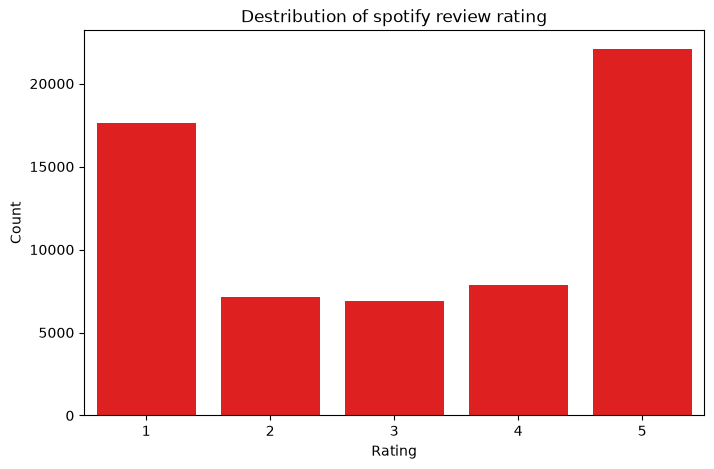

In [24]:
plt.figure(figsize=(8,5))
sns.barplot(rating_counts,x='Rating',y='count',color='red')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.title('Destribution of spotify review rating')
plt.show()

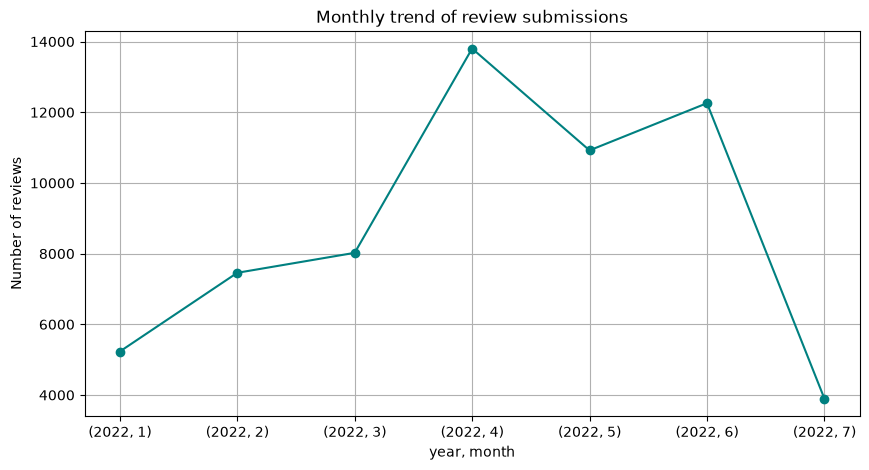

In [30]:
plt.figure(figsize=(10,5))
df.groupby(['year','month']).size().plot(kind='line',marker='o',color='teal')
plt.title('Monthly trend of review submissions')
plt.xlabel('year, month')
plt.ylabel('Number of reviews')
plt.grid(True)
plt.show()

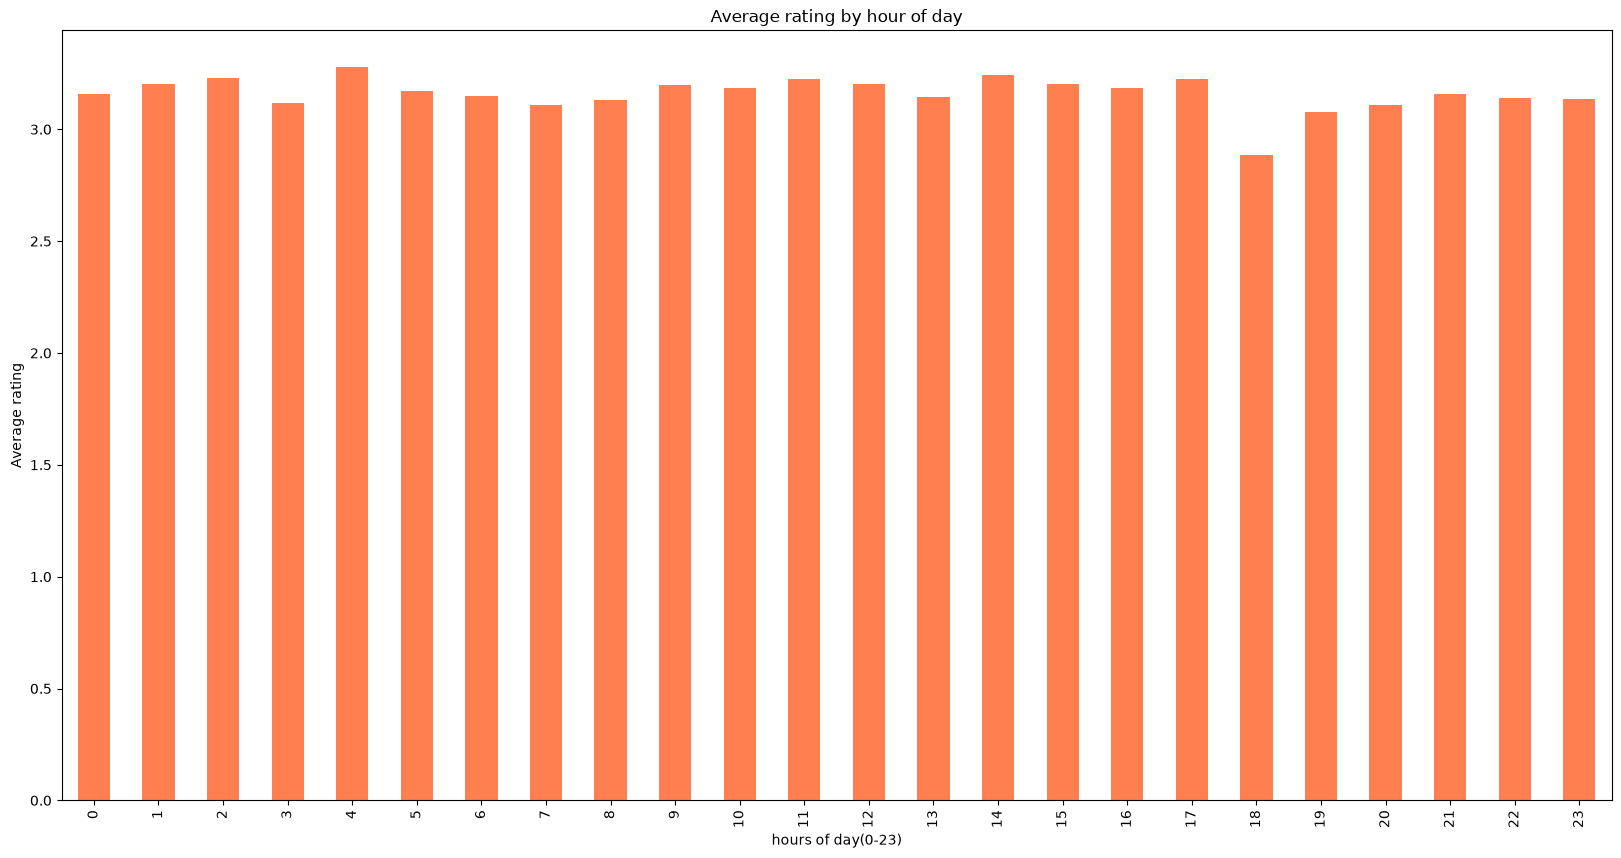

In [35]:
plt.figure(figsize=(20,10))
df.groupby('hours')['Rating'].mean().plot(kind='bar',color='coral')
plt.title('Average rating by hour of day')
plt.xlabel('hours of day(0-23)')
plt.ylabel('Average rating')
plt.show()

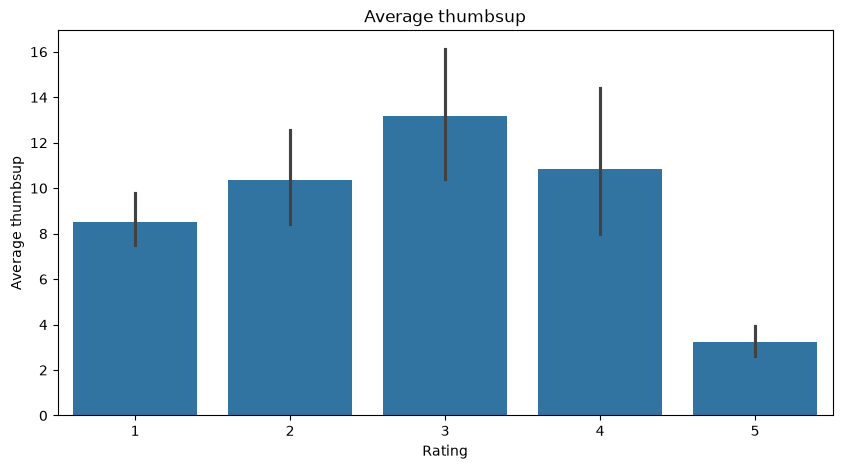

In [36]:
plt.figure(figsize=(10,5))
sns.barplot(df,x='Rating',y='Total_thumbsup')
plt.title('Average thumbsup')
plt.xlabel('Rating')
plt.ylabel('Average thumbsup')
plt.show()

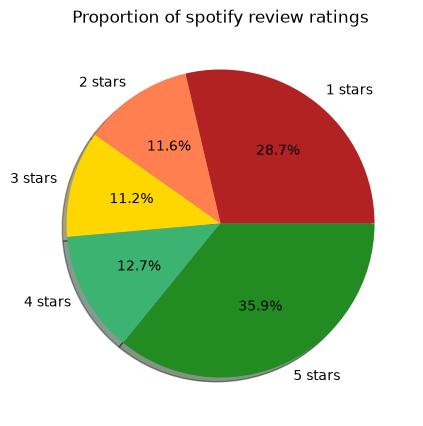

In [46]:
sorted_counts=rating_counts.sort_values('Rating')
plt.figure(figsize=(8,5))
plt.pie(sorted_counts['count'],labels=[f"{r} stars"for r in sorted_counts['Rating']],autopct='%1.1f%%',colors=['firebrick','coral','gold','mediumseagreen','forestgreen'],shadow=True)
plt.title('Proportion of spotify review ratings')
plt.show()